# Timbral features: Random Forest

How well do the 30 timbral features recognise the eight dances, and do the predictions change when only the tempo of the audio changes?

The notebook loads the timbral features, makes the five test folds, trains a default and a tuned Random Forest with nested cross-validation, and then tests the same models on time-stretched audio. `Timbral_SVM_RBF.ipynb` does the same with SVM-RBF.

## 1. Files

The features of the original clips come from `data/ballroom_timbral_features_scratch.csv` (made by `Timbral_extraction.ipynb`). The audio in `BallroomData/` is only needed to compute the stretched versions. The notebook writes `folds.csv`, `timbral_conditions.csv` (the features of all 13 versions, reused by the other timbral notebook) and its results to `results/random_forest/`.

The 30 features are the mean and standard deviation over the frames of 13 MFCCs, the zero-crossing rate and the spectral centroid, computed with our own numpy code (22,050 Hz, frames of 2048 samples, hop 512). Mean and std ignore the order of the frames, so they describe the timbre and not the beat.

In [1]:
from dataclasses import dataclass, field
from pathlib import Path
import os
import platform
import time

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
pd.set_option('display.max_columns', 30)
display(pd.Series({'python': platform.python_version(), 'numpy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'librosa': librosa.__version__}, name='version').to_frame())

,version
python,3.12.13
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
librosa,1.0.0


## 2. Settings

In [2]:
PROJECT_DIR = Path('.')
FEATURES_PATH = PROJECT_DIR / 'data' / 'ballroom_timbral_features_scratch.csv'
DATASET_DIR = Path('BallroomData')

MODEL_NAME = 'Random Forest'
OTHER_MODEL_NAME = 'SVM–RBF'

FOLDS_PATH = PROJECT_DIR / 'folds.csv'
CONDITIONS_PATH = PROJECT_DIR / 'timbral_conditions.csv'
RESULTS_DIR = PROJECT_DIR / 'results' / 'random_forest'
OTHER_RESULTS_DIR = PROJECT_DIR / 'results' / 'svm_rbf'
STRETCH_DIR = RESULTS_DIR / 'time_stretch'

EXPECTED_CLIPS = 698
RANDOM_SEED = 2026
OUTER_FOLDS = 5
INNER_FOLDS = 3
N_JOBS = 8
IMPORTANCE_REPEATS = 5

VARIANTS = ['Default', 'Tuned']
METRICS = ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1']
BLUE, ORANGE = '#2a78d6', '#eb6834'
MODEL_COLORS = {'Random Forest': BLUE, 'SVM–RBF': ORANGE}

if not FEATURES_PATH.is_file():
    raise FileNotFoundError(f'{FEATURES_PATH.resolve()} not found. Put this notebook in the project '
                            'folder next to the CSV files (see section 1), or change PROJECT_DIR.')
STRETCH_DIR.mkdir(parents=True, exist_ok=True)


def save(table, name, **options):
    table.to_csv(RESULTS_DIR / name, **options)


def save_figure(figure, name):
    figure.savefig(RESULTS_DIR / name, bbox_inches='tight')
    plt.show()

## 3. Load the features

Only the 30 feature columns go into the classifier. The three Rumba folders are one class.

In [3]:
FEATURE_COLUMNS = [f'mfcc_{i:02d}_{statistic}' for i in range(13) for statistic in ['mean', 'std']] \
    + ['zcr_mean', 'zcr_std', 'spectral_centroid_mean', 'spectral_centroid_std']


def merge_rumba(labels):
    labels = pd.Series(labels).astype(str)
    return labels.where(~labels.str.startswith('Rumba'), 'Rumba')


data = pd.read_csv(FEATURES_PATH)
missing = sorted(set(['filename', 'folder', 'label'] + FEATURE_COLUMNS) - set(data.columns))
if missing:
    raise ValueError(f'missing columns: {missing}')
if not data['filename'].is_unique:
    raise ValueError('filename must identify one clip')
if not np.isfinite(data[FEATURE_COLUMNS].to_numpy(dtype=float)).all():
    raise ValueError('the features contain NaN or infinite values; check the extraction')
data['label'] = merge_rumba(data['label']).to_numpy()
data = data.sort_values('filename').reset_index(drop=True)

class_labels = np.sort(data['label'].unique())
assert len(data) == EXPECTED_CLIPS and len(class_labels) == 8

FEATURE_GROUPS = {
    'MFCC': [c for c in FEATURE_COLUMNS if c.startswith('mfcc_')],
    'Zero-crossing rate': ['zcr_mean', 'zcr_std'],
    'Spectral centroid': ['spectral_centroid_mean', 'spectral_centroid_std'],
}
print(f'{len(data)} recordings, {len(class_labels)} genres, {len(FEATURE_COLUMNS)} inputs')
display(data['label'].value_counts().sort_index().rename('recordings').to_frame())

698 recordings, 8 genres, 30 inputs


,recordings
label,
ChaChaCha,111
Jive,60
Quickstep,82
Rumba,98
Samba,86
Tango,86
VienneseWaltz,65
Waltz,110


## 4. The five test folds

5-fold cross-validation, stratified by dance. The 13 known duplicate pairs (list from [BallroomAnnotations](https://github.com/CPJKU/BallroomAnnotations)) always stay in the same fold, so a model is never tested on a copy of a training clip. One pair (`Albums-Fire-08` / `-09`) is the same audio with two labels, so one of them is always counted as wrong. Both timbral notebooks make the same folds, and the second one checks that `folds.csv` is identical.

In [4]:
KNOWN_REPLICAS = [   # known duplicate pairs (Fire-08 and Fire-09 have different labels)
    ('Albums-AnaBelen_Veneo-11.wav', 'Albums-Chrisanne2-12.wav'),
    ('Albums-Fire-08.wav', 'Albums-Fire-09.wav'),
    ('Albums-Latin_Jam2-05.wav', 'Albums-Latin_Jam2-13.wav'),
    ('Albums-Secret_Garden-01.wav', 'Media-104705.wav'),
    ('Albums-AnaBelen_Veneo-03.wav', 'Albums-AnaBelen_Veneo-15.wav'),
    ('Albums-Ballroom_Magic-03.wav', 'Albums-Ballroom_Magic-18.wav'),
    ('Albums-Latin_Jam-04.wav', 'Albums-Latin_Jam-13.wav'),
    ('Albums-Latin_Jam-08.wav', 'Albums-Latin_Jam-14.wav'),
    ('Albums-Latin_Jam-06.wav', 'Albums-Latin_Jam-15.wav'),
    ('Albums-Latin_Jam2-02.wav', 'Albums-Latin_Jam2-14.wav'),
    ('Albums-Latin_Jam2-07.wav', 'Albums-Latin_Jam2-15.wav'),
    ('Albums-Latin_Jam3-02.wav', 'Media-103414.wav'),
    ('Media-103402.wav', 'Media-103415.wav'),
]


def make_folds(data):
    folds = data[['filename', 'label']].sort_values('filename').reset_index(drop=True)
    group_of = {name: name.removesuffix('.wav') for name in folds['filename']}
    for first, second in KNOWN_REPLICAS:
        if first in group_of and second in group_of:
            group_of[second] = group_of[first]
    folds['group_id'] = folds['filename'].map(group_of)

    splitter = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    folds['fold'] = -1
    for fold, (_, test_rows) in enumerate(splitter.split(folds, folds['label'], groups=folds['group_id']), start=1):
        folds.loc[test_rows, 'fold'] = fold
    return folds


folds = make_folds(data)
assert (folds['fold'] >= 1).all(), 'every clip needs a fold'
assert (folds.groupby('group_id')['fold'].nunique() == 1).all(), 'a pair is split over two folds'
assert (folds.groupby('fold')['label'].nunique() == len(class_labels)).all(), 'a fold is missing a genre'
if FOLDS_PATH.is_file():
    assert pd.read_csv(FOLDS_PATH).equals(folds), \
        f'{FOLDS_PATH} has different folds; the two models would not be comparable'
    print(f'{FOLDS_PATH} already exists and is identical to the folds made here')
else:
    folds.to_csv(FOLDS_PATH, index=False)
    print(f'saved {FOLDS_PATH}')

data = data.merge(folds[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')

pairs = data[data.duplicated('group_id', keep=False)].sort_values('group_id')
print(f'{data["group_id"].nunique()} groups; {pairs["group_id"].nunique()} known pairs, '
      f'{int((pairs.groupby("group_id")["fold"].nunique() > 1).sum())} of them split over two folds')
print('Pair with two different labels:')
display(pairs[pairs.groupby('group_id')['label'].transform('nunique') > 1][['filename', 'label', 'fold']])
print('Recordings per genre and test fold:')
display(pd.crosstab(data['fold'], data['label'], margins=True))

folds.csv already exists and is identical to the folds made here
685 groups; 13 known pairs, 0 of them split over two folds
Pair with two different labels:


,filename,label,fold
92,Albums-Fire-08.wav,ChaChaCha,1
93,Albums-Fire-09.wav,Samba,1


Recordings per genre and test fold:


label,ChaChaCha,Jive,Quickstep,Rumba,Samba,Tango,VienneseWaltz,Waltz,All
fold,,,,,,,,,
1,22,12,17,20,17,17,13,22,140
2,22,12,17,20,17,17,13,22,140
3,22,12,16,20,17,18,13,22,140
4,22,12,16,19,18,17,13,22,139
5,23,12,16,19,17,17,13,22,139
All,111,60,82,98,86,86,65,110,698


## 5. Random Forest

300 trees. The grid search tries `max_features` (sqrt, 0.5, 1.0), `min_samples_leaf` (1, 2, 4) and `class_weight` (None, balanced), so 18 combinations. The default model uses scikit-learn's standard settings. Trees don't need scaled features.

In [5]:
base_estimator = RandomForestClassifier(
    n_estimators=300, oob_score=True, random_state=RANDOM_SEED, n_jobs=1,
)
parameter_grid = {
    'max_features': ['sqrt', 0.5, 1.0],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced'],
}


def make_search(inner_cv):
    return GridSearchCV(
        estimator=base_estimator,
        param_grid=parameter_grid,
        scoring={'accuracy': 'accuracy', 'macro_f1': 'f1_macro'},
        refit='macro_f1',
        cv=inner_cv,
        n_jobs=N_JOBS,
        error_score='raise',
    )

## 6. Measures

Accuracy, balanced accuracy, macro precision, macro recall, macro-F1 and weighted F1 on the outer test folds, as mean ± SD over the five folds. Macro-F1 is the main one, because it counts every dance equally. Chance is about 16% accuracy and 12.5% balanced accuracy.

In [6]:
def classification_scores(y_true, y_pred):
    def average(metric, how):
        return metric(y_true, y_pred, labels=class_labels, average=how, zero_division=0)
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_precision': average(precision_score, 'macro'),
        'macro_recall': average(recall_score, 'macro'),
        'macro_f1': average(f1_score, 'macro'),
        'weighted_f1': average(f1_score, 'weighted'),
    }


def summarize_folds(fold_metrics, metrics=METRICS, by=('variant',)):
    summary = fold_metrics.groupby(list(by), sort=False)[metrics].agg(['mean', 'std'])
    summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
    return summary.reset_index()


def mean_sd_table(summary, metrics=METRICS, index='variant'):
    return pd.DataFrame({metric: [f'{100*m:.2f} ± {100*s:.2f}' for m, s in
                                  zip(summary[f'{metric}_mean'], summary[f'{metric}_std'])]
                         for metric in metrics}, index=summary[index]).T


def paired_differences(table_a, table_b, metric='macro_f1', names=('A', 'B')):
    a = table_a.set_index(['fold', 'variant'])[metric]
    b = table_b.set_index(['fold', 'variant'])[metric]
    difference = (100*(b - a)).rename(f'{names[1]} - {names[0]} (pp)').reset_index()
    return difference.pivot(index='fold', columns='variant', values=difference.columns[-1])

## 7. Nested cross-validation

For every outer fold, a default and a tuned model are trained on the other four folds. The tuned settings are chosen by a grid search on three inner folds. The test fold is never used for training or tuning.

In [7]:
@dataclass
class CVResults:
    feature_columns: list
    fold_metrics: pd.DataFrame
    predictions: pd.DataFrame
    best_parameters: pd.DataFrame
    models: dict = field(repr=False)


def run_nested_cv(data, feature_columns, verbose=True):
    fold_rows, parameter_rows, models = [], [], {}
    predictions = data[['track_id', 'filename', 'label', 'group_id', 'fold']].copy()
    for variant in VARIANTS:
        predictions[f'prediction_{variant.lower()}'] = ''

    for fold in sorted(data['fold'].unique()):
        train, test = data['fold'] != fold, data['fold'] == fold
        X_train, y_train = data.loc[train, feature_columns], data.loc[train, 'label']
        X_test, y_test = data.loc[test, feature_columns], data.loc[test, 'label']
        assert not set(data.loc[train, 'group_id']) & set(data.loc[test, 'group_id'])

        start = time.perf_counter()
        default = clone(base_estimator).fit(X_train, y_train)
        default_seconds = time.perf_counter() - start

        inner_cv = StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_SEED + fold)
        search = make_search(inner_cv)
        start = time.perf_counter()
        search.fit(X_train, y_train, groups=data.loc[train, 'group_id'])
        tuned_seconds = time.perf_counter() - start
        tuned = search.best_estimator_

        models[fold] = {'Default': default, 'Tuned': tuned}
        for variant, model, seconds in [('Default', default, default_seconds), ('Tuned', tuned, tuned_seconds)]:
            predicted = model.predict(X_test)
            predictions.loc[test, f'prediction_{variant.lower()}'] = predicted
            fold_rows.append({
                'fold': fold, 'variant': variant, **classification_scores(y_test, predicted),
                'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
                'oob_accuracy': getattr(model, 'oob_score_', np.nan),
                'fit_seconds': seconds,
            })
        chosen = {name: ('None' if value is None else value) for name, value in search.best_params_.items()}
        parameter_rows.append({'fold': fold, 'inner_best_macro_f1': search.best_score_, **chosen})
        if verbose:
            d, t = fold_rows[-2], fold_rows[-1]
            print(f'fold {fold}: accuracy default {d["accuracy"]:.3f} / tuned {t["accuracy"]:.3f}, '
                  f'macro-F1 default {d["macro_f1"]:.3f} / tuned {t["macro_f1"]:.3f} '
                  f'(tuning {tuned_seconds:.1f} s)', flush=True)

    for variant in VARIANTS:
        assert (predictions[f'prediction_{variant.lower()}'] != '').all(), 'a clip was never tested'
    return CVResults(feature_columns, pd.DataFrame(fold_rows), predictions,
                     pd.DataFrame(parameter_rows), models)


cv = run_nested_cv(data, FEATURE_COLUMNS)
save(cv.fold_metrics, 'fold_metrics.csv', index=False)
save(cv.predictions, 'out_of_fold_predictions.csv', index=False)
save(cv.best_parameters, 'best_parameters.csv', index=False)

fold 1: accuracy default 0.493 / tuned 0.521, macro-F1 default 0.444 / tuned 0.507 (tuning 14.7 s)


fold 2: accuracy default 0.507 / tuned 0.521, macro-F1 default 0.424 / tuned 0.492 (tuning 10.4 s)


fold 3: accuracy default 0.486 / tuned 0.471, macro-F1 default 0.471 / tuned 0.460 (tuning 10.4 s)


fold 4: accuracy default 0.460 / tuned 0.439, macro-F1 default 0.425 / tuned 0.423 (tuning 11.0 s)


fold 5: accuracy default 0.518 / tuned 0.532, macro-F1 default 0.478 / tuned 0.521 (tuning 10.4 s)


## 8. Results on the original audio

The pooled numbers use all 698 test predictions at once, so they are not exactly the average of the five folds.

In [8]:
summary = summarize_folds(cv.fold_metrics)
save(summary, 'metric_summary.csv', index=False)
print('Five outer test folds, mean ± SD (%)')
display(mean_sd_table(summary))

pooled = pd.DataFrame([{'variant': v, **classification_scores(cv.predictions['label'],
                                                              cv.predictions[f'prediction_{v.lower()}'])}
                       for v in VARIANTS])
save(pooled, 'pooled_metrics.csv', index=False)
print('Pooled over all 698 test predictions')
display(pooled.round(4))

tuning = cv.fold_metrics.pivot(index='fold', columns='variant', values='macro_f1')
tuning['Tuned - Default (pp)'] = 100*(tuning['Tuned'] - tuning['Default'])
display(tuning.round(4))
print(f'Mean macro-F1 change from tuning: {tuning["Tuned - Default (pp)"].mean():+.2f} percentage points')

Five outer test folds, mean ± SD (%)


variant,Default,Tuned
accuracy,49.28 ± 2.20,49.71 ± 4.02
balanced_accuracy,45.92 ± 2.18,48.39 ± 4.09
macro_precision,47.82 ± 4.15,48.82 ± 4.20
macro_recall,45.92 ± 2.18,48.39 ± 4.09
macro_f1,44.85 ± 2.51,48.05 ± 3.94
weighted_f1,47.15 ± 1.74,49.25 ± 3.99


Pooled over all 698 test predictions


,variant,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Default,0.4928,0.4590,0.4749,0.4590,0.4509,0.4732
1,Tuned,0.4971,0.4837,0.4806,0.4837,0.4810,0.4932


variant,Default,Tuned,Tuned - Default (pp)
fold,,,
1,0.4442,0.5065,6.2362
2,0.4242,0.4919,6.7721
3,0.4706,0.4602,-1.0456
4,0.4252,0.4227,-0.2580
5,0.4781,0.5210,4.2908


Mean macro-F1 change from tuning: +3.20 percentage points


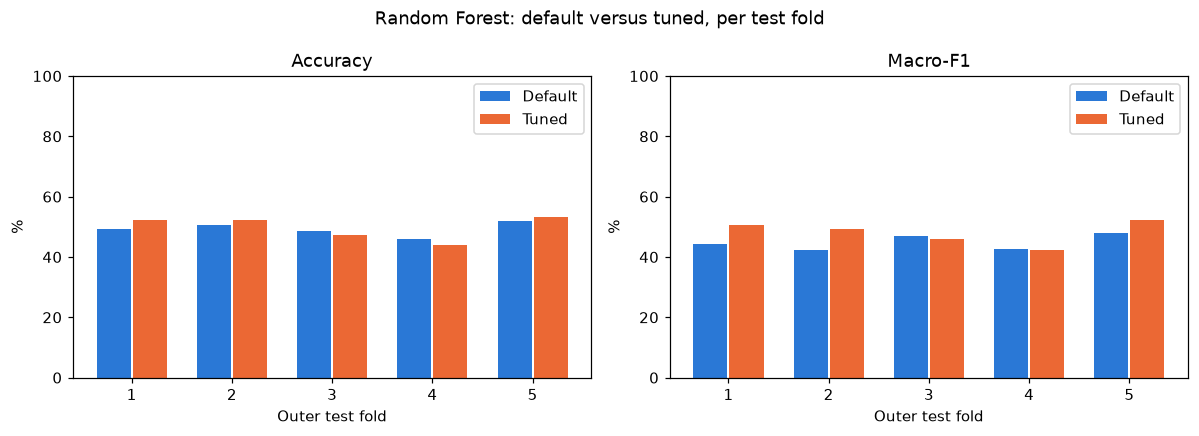

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, metric, title in zip(axes, ['accuracy', 'macro_f1'], ['Accuracy', 'Macro-F1']):
    table = cv.fold_metrics.pivot(index='fold', columns='variant', values=metric)[VARIANTS]
    positions = np.arange(len(table))
    for k, (variant, color) in enumerate(zip(VARIANTS, [BLUE, ORANGE])):
        axis.bar(positions + (k - 0.5)*0.36, 100*table[variant], width=0.34, color=color, label=variant)
    axis.set_xticks(positions, table.index)
    axis.set(title=title, xlabel='Outer test fold', ylabel='%', ylim=(0, 100))
    axis.legend(loc='upper right')
figure.suptitle(f'{MODEL_NAME}: default versus tuned, per test fold')
figure.tight_layout()
save_figure(figure, 'fold_performance.png')

## 9. Chosen settings

The settings each fold chose, and the out-of-bag accuracy, which is a better overfitting check for a forest than the training accuracy.

In [10]:
display(cv.best_parameters.round(4))
display(cv.fold_metrics[['fold', 'variant', 'train_accuracy', 'oob_accuracy', 'accuracy', 'macro_f1']].round(4))

,fold,inner_best_macro_f1,class_weight,max_features,min_samples_leaf
0,1,0.4737,balanced,sqrt,1
1,2,0.4829,balanced,sqrt,1
2,3,0.4739,balanced,sqrt,1
3,4,0.4933,balanced,sqrt,1
4,5,0.4631,balanced,sqrt,4


,fold,variant,train_accuracy,oob_accuracy,accuracy,macro_f1
0,1,Default,1.000,0.4946,0.4929,0.4442
1,1,Tuned,1.000,0.5054,0.5214,0.5065
2,2,Default,1.000,0.5036,0.5071,0.4242
3,2,Tuned,1.000,0.4839,0.5214,0.4919
4,3,Default,1.000,0.4839,0.4857,0.4706
5,3,Tuned,1.000,0.5018,0.4714,0.4602
6,4,Default,1.000,0.5134,0.4604,0.4252
7,4,Tuned,1.000,0.5098,0.4388,0.4227
8,5,Default,1.000,0.4580,0.5180,0.4781
9,5,Tuned,0.975,0.4705,0.5324,0.5210


## 10. Confusion matrices and errors

Rows are the true dances, columns the predictions. The second figure is normalised per row, so the diagonal is the recall of each dance.

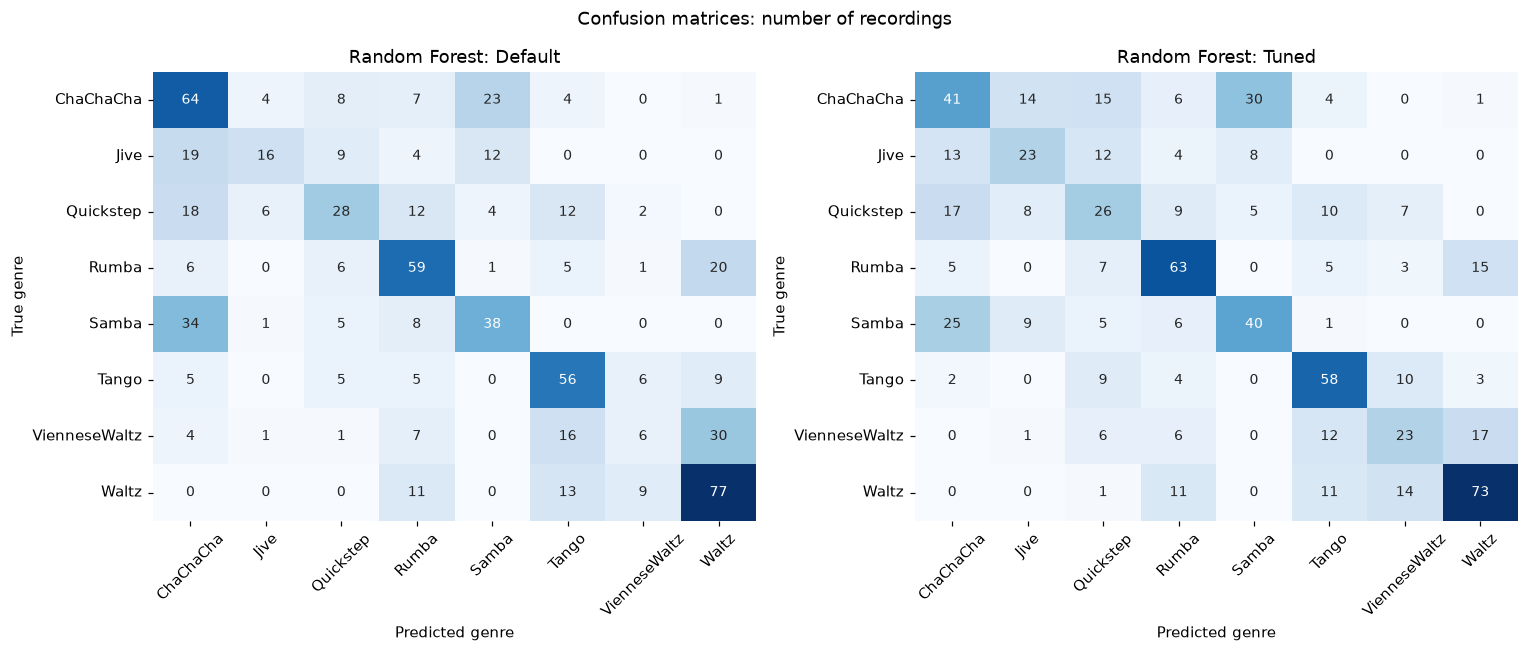

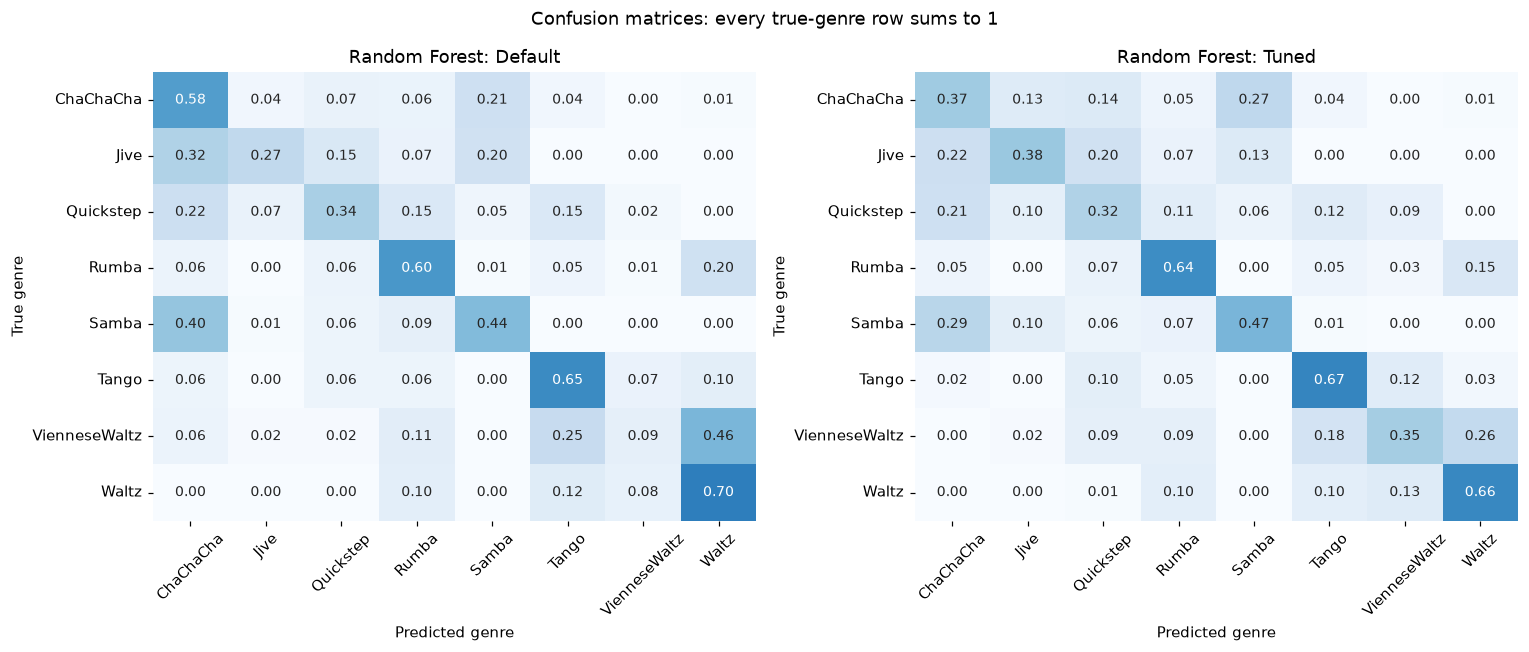

In [11]:
def confusion_tables(y_true, y_pred):
    counts = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=class_labels),
                          index=class_labels, columns=class_labels)
    return counts, counts.div(counts.sum(axis=1), axis=0)


def plot_confusions(tables, titles, fmt, suptitle, ncols=2):
    nrows = int(np.ceil(len(tables)/ncols))
    figure, axes = plt.subplots(nrows, ncols, figsize=(7*ncols, 6*nrows), squeeze=False)
    for axis in axes.flat[len(tables):]:
        axis.set_visible(False)
    for axis, table, title in zip(axes.flat, tables, titles):
        sns.heatmap(table, annot=True, fmt=fmt, cmap='Blues', cbar=False, ax=axis,
                    vmin=0, vmax=None if fmt == 'd' else 1, annot_kws={'size': 9})
        axis.set(title=title, xlabel='Predicted genre', ylabel='True genre')
        axis.tick_params(axis='x', rotation=45)
        axis.tick_params(axis='y', rotation=0)
    figure.suptitle(suptitle)
    figure.tight_layout()
    return figure


def per_genre_report(y_true, y_pred):
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=class_labels,
                                                output_dict=True, zero_division=0)).T.loc[class_labels]
    report['support'] = report['support'].astype(int)
    return report


confusions = {v: confusion_tables(cv.predictions['label'], cv.predictions[f'prediction_{v.lower()}'])
              for v in VARIANTS}
for variant, (counts, normalized) in confusions.items():
    save(counts, f'confusion_counts_{variant.lower()}.csv')
    save(normalized, f'confusion_normalized_{variant.lower()}.csv')
titles = [f'{MODEL_NAME}: {v}' for v in VARIANTS]
save_figure(plot_confusions([confusions[v][0] for v in VARIANTS], titles, 'd',
                            'Confusion matrices: number of recordings'), 'confusion_counts.png')
save_figure(plot_confusions([confusions[v][1] for v in VARIANTS], titles, '.2f',
                            'Confusion matrices: every true-genre row sums to 1'), 'confusion_normalized.png')

In [12]:
for variant in VARIANTS:
    report = per_genre_report(cv.predictions['label'], cv.predictions[f'prediction_{variant.lower()}'])
    save(report, f'per_genre_report_{variant.lower()}.csv', index_label='genre')
    print(f'{variant}: per-genre precision, recall and F1')
    display(report.round(4))

counts = confusions['Tuned'][0]
errors = pd.DataFrame([{'true_genre': t, 'predicted_genre': p, 'clips': int(counts.loc[t, p]),
                        'share_of_true_genre': counts.loc[t, p]/counts.loc[t].sum()}
                       for t in class_labels for p in class_labels if t != p and counts.loc[t, p] > 0])
errors = errors.sort_values('clips', ascending=False).head(10).reset_index(drop=True)
save(errors, 'common_errors_tuned.csv', index=False)
print('Most common errors of the tuned model')
display(errors.round(4))

Default: per-genre precision, recall and F1


,precision,recall,f1-score,support
ChaChaCha,0.4267,0.5766,0.4904,111
Jive,0.5714,0.2667,0.3636,60
Quickstep,0.4516,0.3415,0.3889,82
Rumba,0.5221,0.6020,0.5592,98
Samba,0.4872,0.4419,0.4634,86
Tango,0.5283,0.6512,0.5833,86
VienneseWaltz,0.2500,0.0923,0.1348,65
Waltz,0.5620,0.7000,0.6235,110


Tuned: per-genre precision, recall and F1


,precision,recall,f1-score,support
ChaChaCha,0.3981,0.3694,0.3832,111
Jive,0.4182,0.3833,0.4000,60
Quickstep,0.3210,0.3171,0.3190,82
Rumba,0.5780,0.6429,0.6087,98
Samba,0.4819,0.4651,0.4734,86
Tango,0.5743,0.6744,0.6203,86
VienneseWaltz,0.4035,0.3538,0.3770,65
Waltz,0.6697,0.6636,0.6667,110


Most common errors of the tuned model


,true_genre,predicted_genre,clips,share_of_true_genre
0,ChaChaCha,Samba,30,0.2703
1,Samba,ChaChaCha,25,0.2907
2,Quickstep,ChaChaCha,17,0.2073
3,VienneseWaltz,Waltz,17,0.2615
4,Rumba,Waltz,15,0.1531
5,ChaChaCha,Quickstep,15,0.1351
6,ChaChaCha,Jive,14,0.1261
7,Waltz,VienneseWaltz,14,0.1273
8,Jive,ChaChaCha,13,0.2167
9,VienneseWaltz,Tango,12,0.1846


## 11. Which features the model uses

We shuffle one group of features at a time (MFCC, zero-crossing rate, centroid) across the test clips and look at how much macro-F1 drops.

,mean macro-F1 drop (pp),SD over folds (pp)
feature_family,,
MFCC,30.54,5.32
Spectral centroid,4.72,4.18
Zero-crossing rate,1.73,2.93


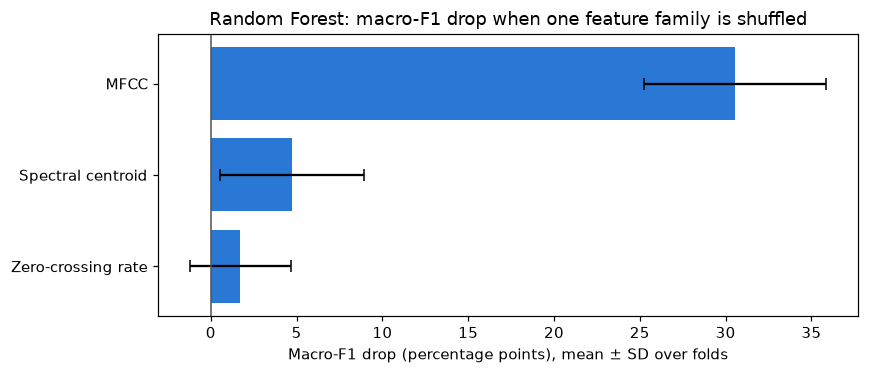

In [13]:
rows = []
for fold, fold_models in cv.models.items():
    test = data['fold'] == fold
    X_test, y_test = data.loc[test, FEATURE_COLUMNS], data.loc[test, 'label']
    model = fold_models['Tuned']
    baseline = f1_score(y_test, model.predict(X_test), average='macro', zero_division=0)
    for family, columns in FEATURE_GROUPS.items():
        for repeat in range(IMPORTANCE_REPEATS):
            order = np.random.default_rng(RANDOM_SEED + 100*fold + repeat).permutation(len(X_test))
            shuffled = X_test.copy()
            shuffled[columns] = X_test[columns].to_numpy()[order]
            score = f1_score(y_test, model.predict(shuffled), average='macro', zero_division=0)
            rows.append({'fold': fold, 'feature_family': family, 'macro_f1_drop': baseline - score})

per_fold = pd.DataFrame(rows).groupby(['fold', 'feature_family'])['macro_f1_drop'].mean()
importance = per_fold.groupby('feature_family').agg(['mean', 'std']).sort_values('mean', ascending=False)
save(importance, 'feature_family_importance.csv')
display((100*importance).rename(columns={'mean': 'mean macro-F1 drop (pp)', 'std': 'SD over folds (pp)'}).round(2))

figure, axis = plt.subplots(figsize=(8, 3.5))
positions = np.arange(len(importance))
axis.barh(positions, 100*importance['mean'], xerr=100*importance['std'], color=BLUE, capsize=4)
axis.set_yticks(positions, importance.index)
axis.invert_yaxis()
axis.axvline(0, color='#52514e', linewidth=1)
axis.set(title=f'{MODEL_NAME}: macro-F1 drop when one feature family is shuffled',
         xlabel='Macro-F1 drop (percentage points), mean ± SD over folds')
figure.tight_layout()
save_figure(figure, 'feature_family_importance.png')

## 12. Without `mfcc_00`

`mfcc_00` is mostly loudness, which depends on the album's mastering. To check that the model isn't just recognising albums, we run the same cross-validation without it (28 inputs). The main model stays the one with all 30 inputs.

In [14]:
without_c0 = [c for c in FEATURE_COLUMNS if not c.startswith('mfcc_00')]
cv_without_c0 = run_nested_cv(data, without_c0, verbose=False)

feature_check = pd.concat([
    summarize_folds(cv.fold_metrics, ['accuracy', 'macro_f1']).assign(inputs='all 30'),
    summarize_folds(cv_without_c0.fold_metrics, ['accuracy', 'macro_f1']).assign(inputs='without mfcc_00 (28)'),
])
feature_check['label'] = feature_check['inputs'] + ', ' + feature_check['variant']
save(feature_check, 'feature_check_without_mfcc00.csv', index=False)
display(mean_sd_table(feature_check, ['accuracy', 'macro_f1'], index='label'))
print('Per fold: macro-F1 without mfcc_00 minus with it (percentage points)')
display(paired_differences(cv.fold_metrics, cv_without_c0.fold_metrics,
                           names=('all 30', 'without mfcc_00')).round(2))

label,"all 30, Default","all 30, Tuned","without mfcc_00 (28), Default","without mfcc_00 (28), Tuned"
accuracy,49.28 ± 2.20,49.71 ± 4.02,47.99 ± 1.62,45.56 ± 3.62
macro_f1,44.85 ± 2.51,48.05 ± 3.94,44.62 ± 2.21,43.75 ± 4.18


Per fold: macro-F1 without mfcc_00 minus with it (percentage points)


variant,Default,Tuned
fold,,
1,1.36,-1.38
2,-0.16,-9.75
3,-2.07,-5.20
4,0.07,0.04
5,-0.31,-5.19


## 13. Random Forest vs SVM-RBF

Both notebooks use the same folds, so we compare them fold by fold. The forest splits on one feature at a time, while the SVM compares whole feature vectors after scaling. This needs `Timbral_SVM_RBF.ipynb` to have run first.

In [15]:
other_metrics_path = OTHER_RESULTS_DIR / 'fold_metrics.csv'
other_predictions_path = OTHER_RESULTS_DIR / 'out_of_fold_predictions.csv'

if other_metrics_path.is_file() and other_predictions_path.is_file():
    other_metrics = pd.read_csv(other_metrics_path)
    other_folds = pd.read_csv(other_predictions_path).set_index('filename')['fold']
    this_folds = cv.predictions.set_index('filename')['fold']
    assert other_folds.loc[this_folds.index].equals(this_folds), 'the two notebooks used different folds'

    both = pd.concat([summarize_folds(cv.fold_metrics, ['accuracy', 'macro_f1']).assign(model=MODEL_NAME),
                      summarize_folds(other_metrics, ['accuracy', 'macro_f1']).assign(model=OTHER_MODEL_NAME)])
    both['label'] = both['model'] + ', ' + both['variant']
    print('Same recordings and folds, mean ± SD (%)')
    display(mean_sd_table(both, ['accuracy', 'macro_f1'], index='label'))
    print(f'Per fold: macro-F1 of {MODEL_NAME} minus {OTHER_MODEL_NAME} (percentage points)')
    display(paired_differences(other_metrics, cv.fold_metrics, names=(OTHER_MODEL_NAME, MODEL_NAME)).round(2))
else:
    print(f'Run the {OTHER_MODEL_NAME} notebook, then rerun this cell to compare the two models.')

Same recordings and folds, mean ± SD (%)


label,"Random Forest, Default","Random Forest, Tuned","SVM–RBF, Default","SVM–RBF, Tuned"
accuracy,49.28 ± 2.20,49.71 ± 4.02,50.14 ± 4.43,50.58 ± 3.86
macro_f1,44.85 ± 2.51,48.05 ± 3.94,46.63 ± 4.35,48.86 ± 4.49


Per fold: macro-F1 of Random Forest minus SVM–RBF (percentage points)


variant,Default,Tuned
fold,,
1,-0.10,7.06
2,-9.41,3.90
3,1.35,-4.88
4,1.50,-7.48
5,-2.27,-2.69


---
## 14. Time-stretch experiment

Every clip is used in 13 versions: the original, stretched by ±2%, ±5% and ±10% (librosa's phase vocoder, same pitch), and the same six stretches as round trips (stretched and stretched back). If a model gets worse on a stretched version but not on its round trip, the change comes from the tempo. If both drop, it comes from the processing.

In [16]:
RATES = [0.90, 0.95, 0.98, 1.02, 1.05, 1.10]


def make_condition(kind, rate):
    name = 'original' if kind == 'original' else f'{kind}_{rate:.2f}'
    tempo_change = 100*(rate - 1) if kind == 'stretch' else 0.0
    return {'condition': name, 'kind': kind, 'rate': rate, 'tempo_change_percent': round(tempo_change, 6)}


CONDITIONS = ([make_condition('original', 1.0)]
              + [make_condition('stretch', rate) for rate in RATES]
              + [make_condition('roundtrip', rate) for rate in RATES])


def change_tempo(y, rate):
    # faster or slower, same pitch
    if rate == 1.0:
        return y
    stretched = librosa.effects.time_stretch(y.astype(np.float64), rate=rate, n_fft=2048, hop_length=512)
    return stretched.astype(np.float32)


def apply_condition(y, condition):
    if condition['kind'] == 'original':
        return y
    if condition['kind'] == 'stretch':
        return change_tempo(y, condition['rate'])
    if condition['kind'] == 'roundtrip':
        return change_tempo(change_tempo(y, condition['rate']), 1.0/condition['rate'])
    raise ValueError(f'unknown condition: {condition}')


display(pd.DataFrame(CONDITIONS))

,condition,kind,rate,tempo_change_percent
0,original,original,1.00,0.0
1,stretch_0.90,stretch,0.90,-10.0
2,stretch_0.95,stretch,0.95,-5.0
3,stretch_0.98,stretch,0.98,-2.0
4,stretch_1.02,stretch,1.02,2.0
5,stretch_1.05,stretch,1.05,5.0
6,stretch_1.10,stretch,1.10,10.0
7,roundtrip_0.90,roundtrip,0.90,0.0
8,roundtrip_0.95,roundtrip,0.95,0.0
9,roundtrip_0.98,roundtrip,0.98,0.0


## 15. Features of the stretched clips

Computed with the same code as the training table and saved in `timbral_conditions.csv` (about 15 minutes the first time, reused after that). If the run stops, running the cell again continues where it stopped.

In [17]:
SR, N_FFT, HOP_LENGTH, N_MFCC, N_MELS = 22050, 2048, 512, 13, 128


def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    if len(y) < N_FFT:
        raise ValueError('audio is too short')
    if np.max(np.abs(y)) == 0:
        raise ValueError('audio is silent')
    return y


def count_zero_crossings(samples, N, hop):
    pos = samples >= 0
    counts = []
    for n in range(0, len(samples)-N+1, hop):
        chunk = pos[n:n+N]
        counts.append(np.count_nonzero(chunk[1:] != chunk[:-1]))
    return np.array(counts)


def centroid(samples, N, hop, fs):
    out = []
    for n in range(0, len(samples)-N+1, hop):
        mag = abs(np.fft.rfft(samples[n:n+N]))
        freqs = fs*np.arange(len(mag))/N
        out.append(np.sum(freqs*mag)/np.sum(mag))
    return np.array(out)


def hz_to_mel(f):
    if f < 1000:
        return 3*f/200
    return 15 + 27*np.log(f/1000)/np.log(6.4)


def mel_to_hz(m):
    low = 200*m/3
    high = 1000*np.exp((m - 15)*np.log(6.4)/27)
    return np.where(m < 15, low, high)


def mel_filterbank(N, fs, n_mels=128):
    freqs = fs*np.arange(N//2 + 1)/N
    edges = mel_to_hz(np.linspace(0, hz_to_mel(fs/2), n_mels + 2))
    fb = np.zeros((n_mels, len(freqs)))
    for m in range(n_mels):
        left, mid, right = edges[m], edges[m+1], edges[m+2]
        up = (freqs - left)/(mid - left)
        down = (right - freqs)/(right - mid)
        fb[m] = np.maximum(0, np.minimum(up, down))
        fb[m] = fb[m]*2/(right - left)
    return fb


def mfcc_from_scratch(samples, N, hop, fs, n_mfcc=13, n_mels=128):
    w = np.hanning(N)
    fb = mel_filterbank(N, fs, n_mels)

    energies = []
    for n in range(0, len(samples)-N+1, hop):
        power = abs(np.fft.rfft(samples[n:n+N]*w))**2
        energies.append(fb @ power)
    energies = np.array(energies)

    # keep the top 80 dB, like librosa
    log_e = 10*np.log10(energies + 1e-10)
    log_e = np.maximum(log_e, log_e.max() - 80)

    # same DCT scaling as librosa
    i = np.arange(n_mfcc).reshape(-1, 1)
    m = np.arange(n_mels).reshape(1, -1)
    dct = np.cos(np.pi*i/n_mels*(m + 0.5))*np.sqrt(2/n_mels)
    dct[0] = dct[0]/np.sqrt(2)

    return dct @ log_e.T


def timbral_features(y):
    mfcc = mfcc_from_scratch(y, N_FFT, HOP_LENGTH, SR, N_MFCC, N_MELS)
    zcr = count_zero_crossings(y, N_FFT, HOP_LENGTH)/N_FFT
    with np.errstate(invalid='ignore'):
        sc = np.nan_to_num(centroid(y, N_FFT, HOP_LENGTH, SR))   # silent frames give 0/0
    feats = {}
    for i in range(N_MFCC):
        feats[f'mfcc_{i:02d}_mean'] = float(np.mean(mfcc[i]))
        feats[f'mfcc_{i:02d}_std'] = float(np.std(mfcc[i]))
    feats['zcr_mean'], feats['zcr_std'] = float(np.mean(zcr)), float(np.std(zcr))
    feats['spectral_centroid_mean'], feats['spectral_centroid_std'] = float(np.mean(sc)), float(np.std(sc))
    return feats


def condition_rows(path, clip):
    try:
        y = load_audio(path)
        rows = []
        for condition in CONDITIONS:
            y_condition = apply_condition(y, condition)
            rows.append({**clip, **condition, 'duration': len(y_condition)/SR,
                         'original_duration': len(y)/SR, **timbral_features(y_condition)})
        return rows, None
    except Exception as e:
        return [], {'filename': clip['filename'], 'error': repr(e)}


def is_complete(path):
    if not path.is_file():
        return False
    saved = pd.read_csv(path, usecols=['filename', 'condition'])
    return (len(saved) == len(data)*len(CONDITIONS) and set(saved['filename']) == set(data['filename'])
            and set(saved['condition']) == {c['condition'] for c in CONDITIONS})


def extract_conditions(batch_size=25):
    partial = CONDITIONS_PATH.with_name('timbral_conditions_partial.csv')
    done = set(pd.read_csv(partial, usecols=['filename'])['filename']) if partial.is_file() else set()
    todo = data[~data['filename'].isin(done)]
    print(f'{len(done)} clips already done, {len(todo)} to go (using {N_JOBS} cores)')
    failed = []
    for start in range(0, len(todo), batch_size):
        batch = todo.iloc[start:start + batch_size]
        jobs = (delayed(condition_rows)(DATASET_DIR / clip['folder'] / clip['filename'],
                                        {k: clip[k] for k in ['track_id', 'filename', 'folder', 'label']})
                for _, clip in batch.iterrows())
        results = Parallel(n_jobs=N_JOBS)(jobs)
        rows = [row for clip_rows, _ in results for row in clip_rows]
        failed += [error for _, error in results if error is not None]
        if rows:
            pd.DataFrame(rows).to_csv(partial, mode='a', header=not partial.is_file(), index=False)
        print(f'  {len(done) + start + len(batch)} of {len(data)} clips', flush=True)
    if failed:
        raise RuntimeError(f'{len(failed)} clips failed (the others are saved, rerun to retry them): {failed[:5]}')
    table = pd.read_csv(partial)
    table.to_csv(CONDITIONS_PATH, index=False)
    partial.unlink()
    return table


if is_complete(CONDITIONS_PATH):
    source = CONDITIONS_PATH
    print(f'using the saved stretched features in {CONDITIONS_PATH}')
elif DATASET_DIR.is_dir():
    start = time.perf_counter()
    extract_conditions()
    source = CONDITIONS_PATH
    print(f'computed in {(time.perf_counter() - start)/60:.1f} minutes')
else:
    source = None
    print(f'No audio in {DATASET_DIR.resolve()} and no saved stretched features: '
          'sections 15-20 are skipped. Extract data1.tar.gz into the project folder and rerun from here.')
STRETCH_READY = source is not None

using the saved stretched features in timbral_conditions.csv


Checks: every clip in every version, the fresh original rows match the training table, and every version has the expected length.

In [18]:
if STRETCH_READY:
    conditions = pd.read_csv(source)
    conditions['label'] = merge_rumba(conditions['label']).to_numpy()
    assert is_complete(source) and not conditions.duplicated(['filename', 'condition']).any()

    fresh = conditions[conditions['condition'] == 'original'].set_index('filename').loc[data['filename'], FEATURE_COLUMNS]
    difference = np.abs(fresh.to_numpy() - data[FEATURE_COLUMNS].to_numpy()).max(axis=0)
    agreement = pd.DataFrame({'largest_difference': difference,
                              'difference_over_spread': difference/data[FEATURE_COLUMNS].std().to_numpy()},
                             index=FEATURE_COLUMNS)
    agreement.to_csv(STRETCH_DIR / 'original_extraction_agreement.csv')
    print(f'fresh original rows vs training table: largest difference / spread = '
          f'{agreement["difference_over_spread"].max():.2e}')
    assert (agreement['difference_over_spread'] < 0.05).all(), \
        'the fresh features differ from the training table; were they made with other settings?'

    expected = np.where(conditions['kind'] == 'stretch', conditions['original_duration']/conditions['rate'],
                        conditions['original_duration'])
    duration_error = np.abs(conditions['duration'] - expected).max()
    print(f'largest duration error: {duration_error*SR:.2f} samples')
    assert duration_error <= 2/SR

fresh original rows vs training table: largest difference / spread = 0.00e+00
largest duration error: 1.00 samples


## 16. Predict every version

The fold models from section 7 are only used for prediction here. Every version keeps its label and test fold, so we compare the same clips with the same model. The flip rate is the share of clips whose prediction changes.

In [19]:
CONDITION_ORDER = pd.DataFrame(CONDITIONS)['condition'].tolist()

if STRETCH_READY:
    by_condition = {name: rows.set_index('filename') for name, rows in conditions.groupby('condition')}
    metric_rows, prediction_rows = [], []
    for fold, fold_models in cv.models.items():
        test_files = data.loc[data['fold'] == fold, 'filename']
        y_test = data.loc[data['fold'] == fold, 'label'].to_numpy()
        for variant, model in fold_models.items():
            baseline = model.predict(by_condition['original'].loc[test_files, FEATURE_COLUMNS])
            baseline_scores = classification_scores(y_test, baseline)
            for condition in CONDITIONS:
                predicted = model.predict(by_condition[condition['condition']].loc[test_files, FEATURE_COLUMNS])
                scores = classification_scores(y_test, predicted)
                metric_rows.append({'fold': fold, 'variant': variant, **condition, **scores,
                                    'flip_rate': np.mean(predicted != baseline),
                                    'accuracy_change_pp': 100*(scores['accuracy'] - baseline_scores['accuracy']),
                                    'macro_f1_change_pp': 100*(scores['macro_f1'] - baseline_scores['macro_f1'])})
                prediction_rows.append(pd.DataFrame({'filename': test_files.to_numpy(), 'label': y_test,
                                                     'fold': fold, 'variant': variant,
                                                     'condition': condition['condition'],
                                                     'prediction': predicted, 'baseline_prediction': baseline}))
    condition_metrics = pd.DataFrame(metric_rows)
    condition_predictions = pd.concat(prediction_rows, ignore_index=True)
    condition_metrics.to_csv(STRETCH_DIR / 'fold_metrics.csv', index=False)
    condition_predictions.to_csv(STRETCH_DIR / 'held_out_predictions.csv', index=False)

    fresh_predictions = condition_predictions[condition_predictions['condition'] == 'original']
    for variant in VARIANTS:
        fresh_variant = fresh_predictions[fresh_predictions['variant'] == variant].set_index('filename')['prediction']
        trained = cv.predictions.set_index('filename')[f'prediction_{variant.lower()}']
        print(f'{variant}: {int((fresh_variant != trained.loc[fresh_variant.index]).sum())} of '
              f'{len(fresh_variant)} predictions differ between the fresh original features and the training table')

Default: 0 of 698 predictions differ between the fresh original features and the training table
Tuned: 0 of 698 predictions differ between the fresh original features and the training table


## 17. Results per version

Mean ± SD over the five test folds; the change is measured against the original audio within each fold. In the plots, the solid line is the stretched audio and the dashed line the round trip.

In [20]:
if STRETCH_READY:
    stretch_summary = summarize_folds(condition_metrics,
                                      ['accuracy', 'macro_f1', 'flip_rate', 'accuracy_change_pp', 'macro_f1_change_pp'],
                                      by=('variant', 'condition', 'kind', 'rate', 'tempo_change_percent'))
    stretch_summary.to_csv(STRETCH_DIR / 'robustness_summary.csv', index=False)

    table = stretch_summary[['variant', 'condition', 'tempo_change_percent']].copy()
    for metric in ['accuracy', 'macro_f1', 'flip_rate']:
        table[f'{metric} (%)'] = [f'{100*m:.2f} ± {100*s:.2f}' for m, s in
                                  zip(stretch_summary[f'{metric}_mean'], stretch_summary[f'{metric}_std'])]
    table['accuracy change (pp)'] = stretch_summary['accuracy_change_pp_mean'].round(2)
    table['macro-F1 change (pp)'] = stretch_summary['macro_f1_change_pp_mean'].round(2)
    display(table.reset_index(drop=True))

,variant,condition,tempo_change_percent,accuracy (%),macro_f1 (%),flip_rate (%),accuracy change (pp),macro-F1 change (pp)
0,Default,original,0.0,49.28 ± 2.20,44.85 ± 2.51,0.00 ± 0.00,0.00,0.00
1,Default,stretch_0.90,-10.0,48.28 ± 1.46,44.19 ± 1.81,14.47 ± 2.67,-1.00,-0.65
2,Default,stretch_0.95,-5.0,48.85 ± 2.08,44.22 ± 1.64,15.19 ± 2.97,-0.43,-0.62
3,Default,stretch_0.98,-2.0,48.56 ± 1.74,44.48 ± 0.64,14.76 ± 3.39,-0.72,-0.36
4,Default,stretch_1.02,2.0,49.00 ± 2.91,45.00 ± 3.25,14.18 ± 2.03,-0.28,0.15
5,Default,stretch_1.05,5.0,49.43 ± 1.90,45.29 ± 1.09,14.76 ± 4.22,0.14,0.44
6,Default,stretch_1.10,10.0,49.00 ± 1.42,45.14 ± 1.24,15.48 ± 3.73,-0.29,0.29
7,Default,roundtrip_0.90,0.0,48.14 ± 3.04,43.92 ± 2.35,20.78 ± 3.53,-1.15,-0.93
8,Default,roundtrip_0.95,0.0,47.13 ± 3.10,41.97 ± 3.34,21.21 ± 4.15,-2.15,-2.88
9,Default,roundtrip_0.98,0.0,47.57 ± 2.13,42.85 ± 1.82,21.36 ± 4.28,-1.72,-1.99


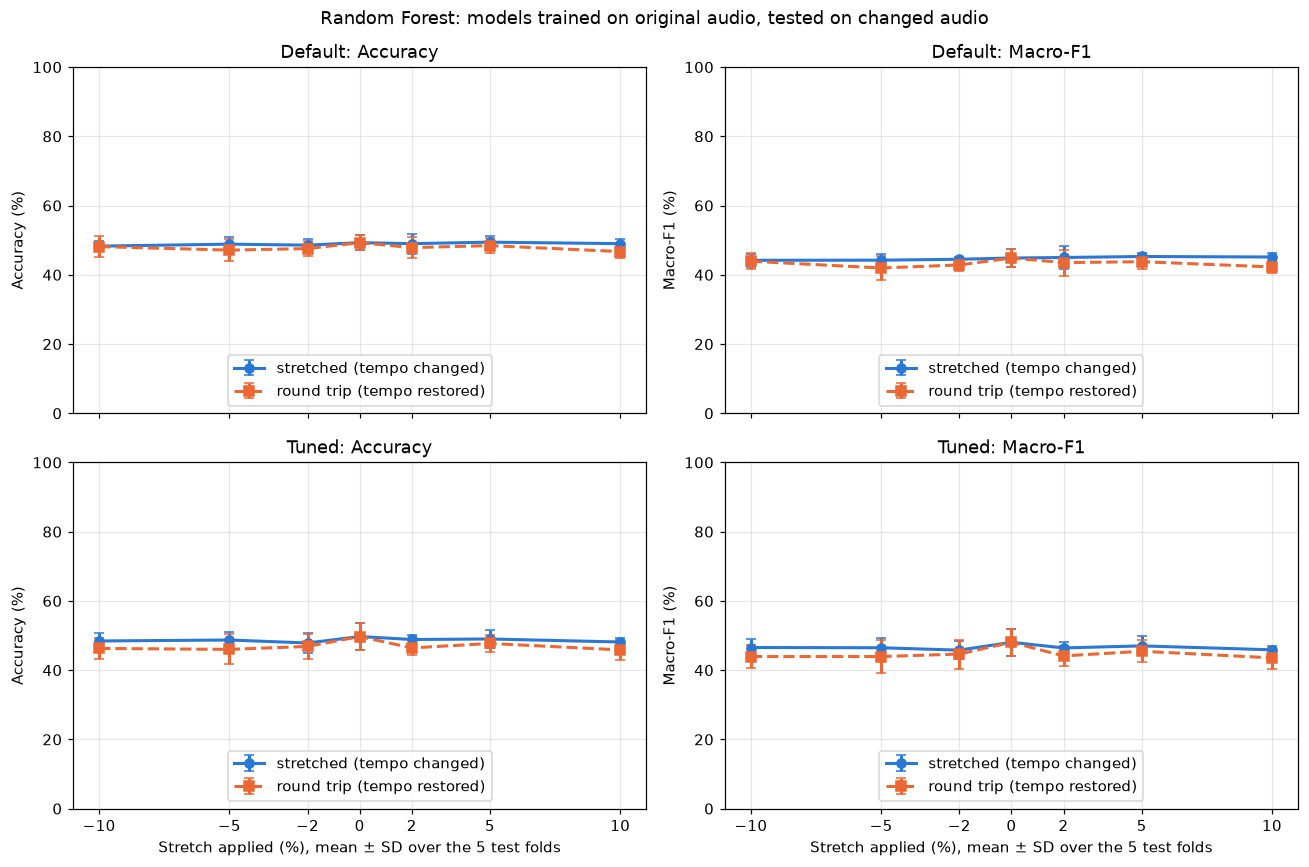

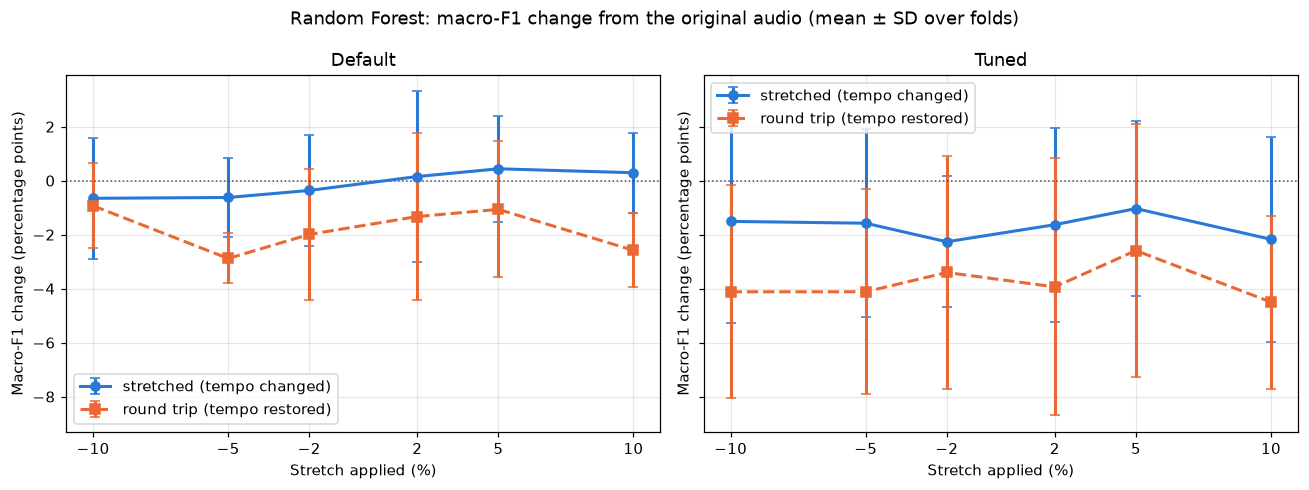

In [21]:
LINES = [('stretch', BLUE, '-', 'o', 'stretched (tempo changed)'),
         ('roundtrip', ORANGE, '--', 's', 'round trip (tempo restored)')]

if STRETCH_READY:
    figure, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    for row, variant in enumerate(VARIANTS):
        rows = stretch_summary[stretch_summary['variant'] == variant]
        for col, (metric, label) in enumerate([('accuracy', 'Accuracy'), ('macro_f1', 'Macro-F1')]):
            axis = axes[row, col]
            for kind, color, style, marker, legend in LINES:
                part = rows[rows['kind'].isin([kind, 'original'])].sort_values('rate')
                axis.errorbar(100*(part['rate'] - 1), 100*part[f'{metric}_mean'], yerr=100*part[f'{metric}_std'],
                              color=color, linestyle=style, marker=marker, markersize=6, linewidth=2,
                              capsize=3, label=legend)
            axis.set(ylim=(0, 100), ylabel=f'{label} (%)', title=f'{variant}: {label}')
            axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
            axis.grid(alpha=0.3)
            axis.legend(loc='lower center')
    for axis in axes[1]:
        axis.set_xlabel('Stretch applied (%), mean ± SD over the 5 test folds')
    figure.suptitle(f'{MODEL_NAME}: models trained on original audio, tested on changed audio')
    figure.tight_layout()
    figure.savefig(STRETCH_DIR / 'robustness_curves.png', bbox_inches='tight')
    plt.show()

    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for axis, variant in zip(axes, VARIANTS):
        rows = stretch_summary[(stretch_summary['variant'] == variant) & (stretch_summary['kind'] != 'original')]
        for kind, color, style, marker, legend in LINES:
            part = rows[rows['kind'] == kind].sort_values('rate')
            axis.errorbar(100*(part['rate'] - 1), part['macro_f1_change_pp_mean'], yerr=part['macro_f1_change_pp_std'],
                          color=color, linestyle=style, marker=marker, markersize=6, linewidth=2, capsize=3,
                          label=legend)
        axis.axhline(0, color='#52514e', linewidth=1, linestyle=':')
        axis.set(title=variant, xlabel='Stretch applied (%)', ylabel='Macro-F1 change (percentage points)')
        axis.set_xticks([-10, -5, -2, 2, 5, 10])
        axis.grid(alpha=0.3)
        axis.legend()
    figure.suptitle(f'{MODEL_NAME}: macro-F1 change from the original audio (mean ± SD over folds)')
    figure.tight_layout()
    figure.savefig(STRETCH_DIR / 'paired_changes.png', bbox_inches='tight')
    plt.show()

## 18. Confusion matrices and per-dance changes

Confusion matrices on the stretched versions, and the change in F1 per dance (blue better, red worse).

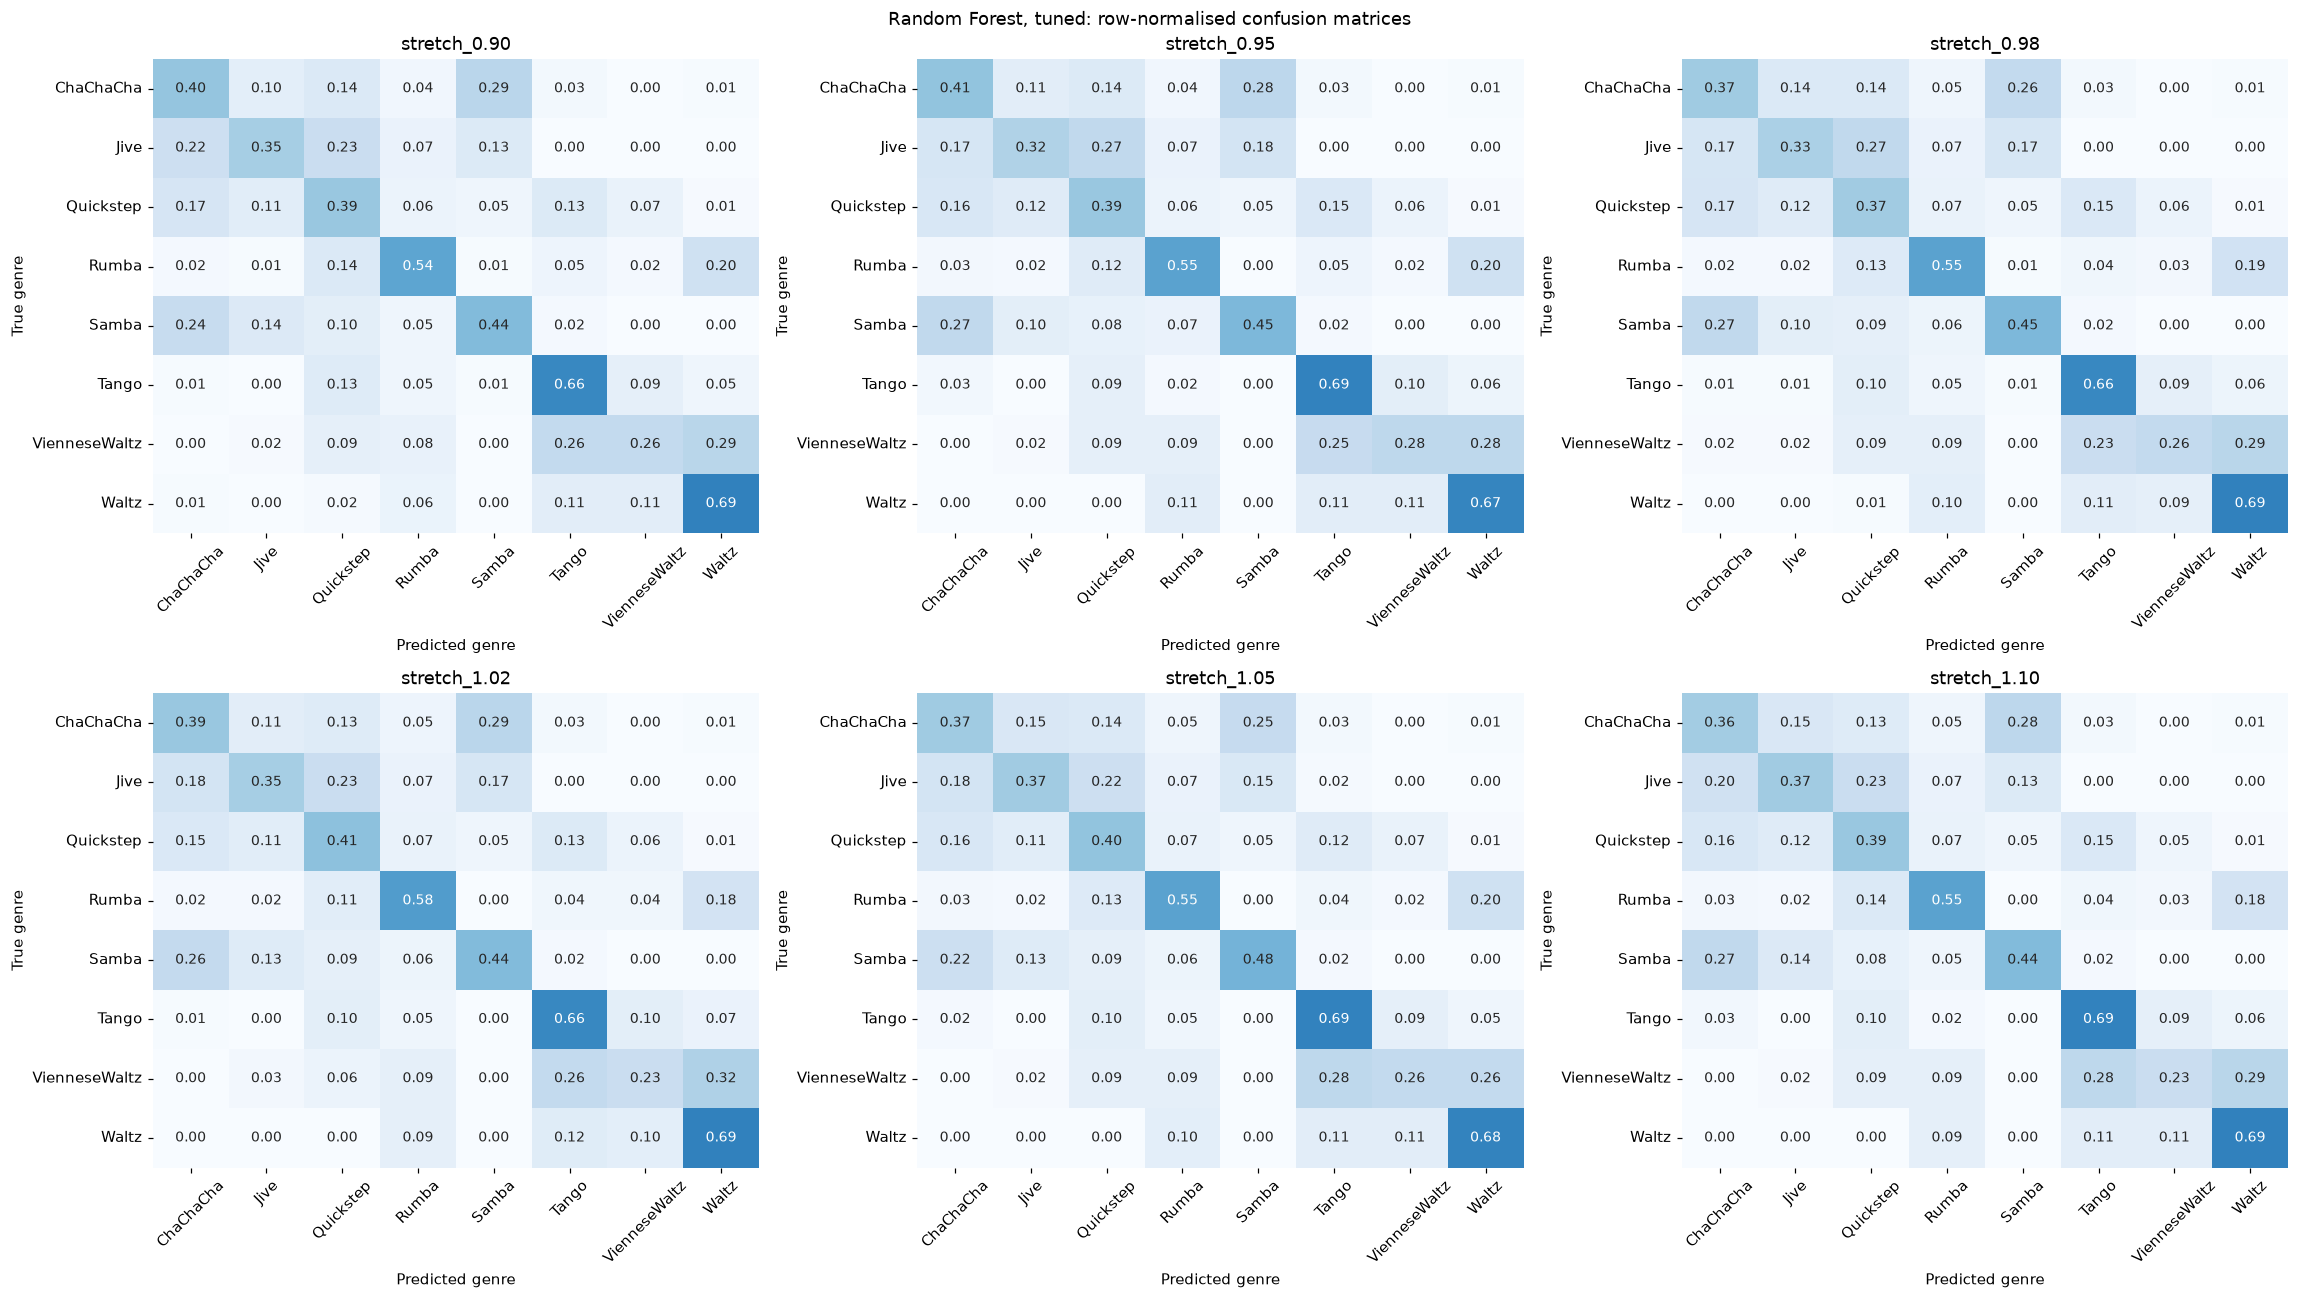

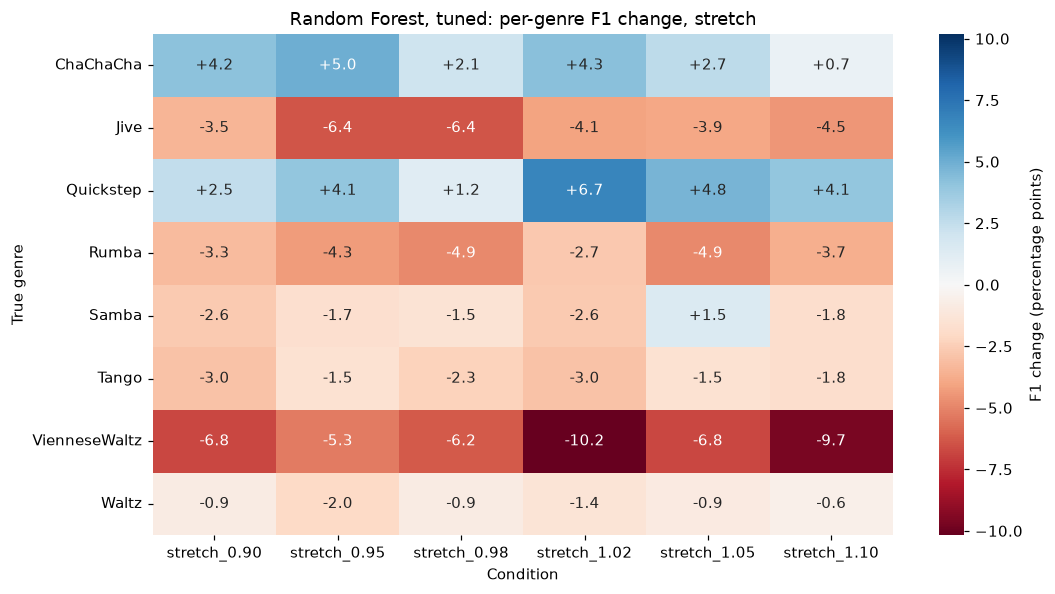

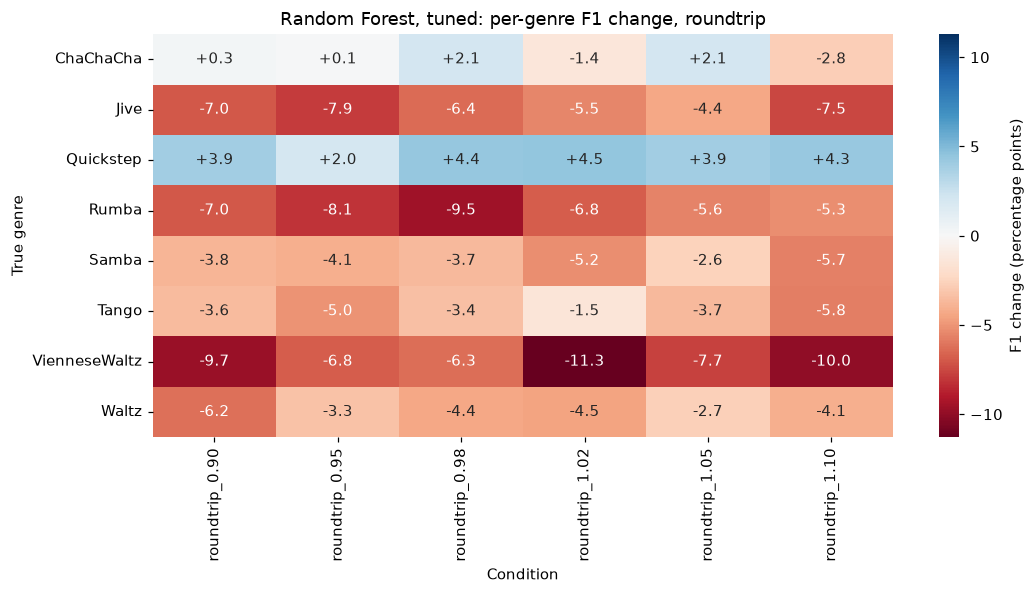

In [22]:
if STRETCH_READY:
    tuned = condition_predictions[condition_predictions['variant'] == 'Tuned']
    stretch_names = [c for c in CONDITION_ORDER if c.startswith('stretch')]
    tables = []
    for name in stretch_names:
        rows = tuned[tuned['condition'] == name]
        tables.append(confusion_tables(rows['label'], rows['prediction'])[1])
    figure = plot_confusions(tables, stretch_names, '.2f', f'{MODEL_NAME}, tuned: row-normalised confusion matrices', ncols=3)
    figure.savefig(STRETCH_DIR / 'confusion_normalized_stretches.png', bbox_inches='tight')
    plt.show()

    f1_by_condition = pd.DataFrame({name: per_genre_report(rows['label'], rows['prediction'])['f1-score']
                                    for name, rows in tuned.groupby('condition')})[CONDITION_ORDER]
    f1_by_condition.to_csv(STRETCH_DIR / 'per_genre_f1_tuned.csv')
    for kind in ['stretch', 'roundtrip']:
        columns = [c for c in CONDITION_ORDER if c.startswith(kind)]
        changes = 100*f1_by_condition[columns].sub(f1_by_condition['original'], axis=0)
        bound = max(1.0, float(np.abs(changes.to_numpy()).max()))
        figure, axis = plt.subplots(figsize=(10, 5.5))
        sns.heatmap(changes, annot=True, fmt='+.1f', cmap='RdBu', center=0, vmin=-bound, vmax=bound, ax=axis,
                    cbar_kws={'label': 'F1 change (percentage points)'})
        axis.set(title=f'{MODEL_NAME}, tuned: per-genre F1 change, {kind}', xlabel='Condition', ylabel='True genre')
        axis.tick_params(axis='y', rotation=0)
        figure.tight_layout()
        figure.savefig(STRETCH_DIR / f'per_genre_f1_change_{kind}.png', bbox_inches='tight')
        plt.show()

## 19. Both classifiers on the stretched audio

This needs the other timbral notebook to have run its time-stretch part.

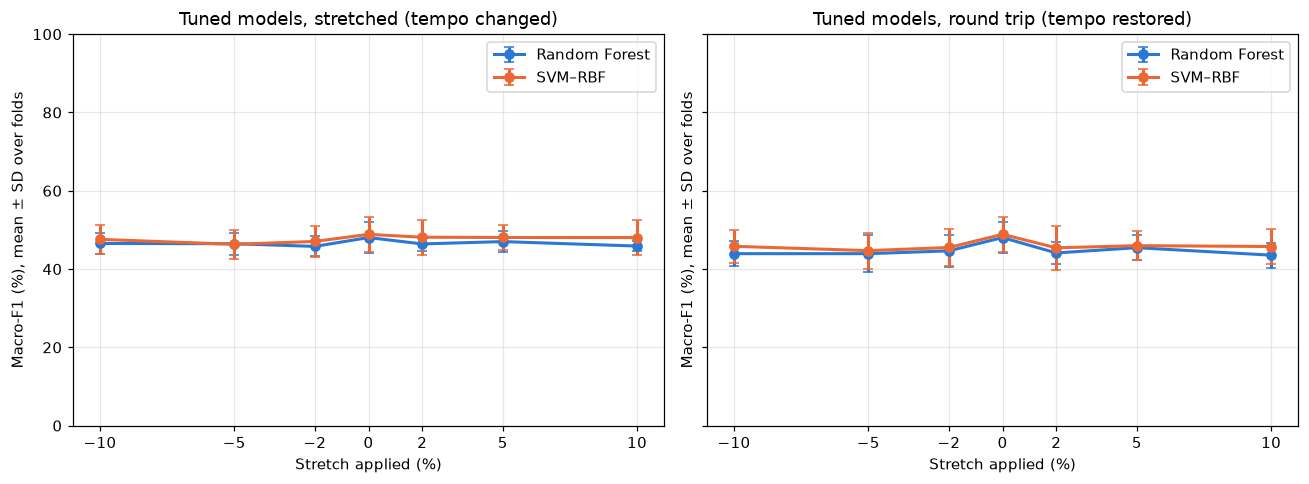

In [23]:
other_summary_path = OTHER_RESULTS_DIR / 'time_stretch' / 'robustness_summary.csv'
if STRETCH_READY and other_summary_path.is_file():
    combined = pd.concat([stretch_summary.assign(model=MODEL_NAME),
                          pd.read_csv(other_summary_path).assign(model=OTHER_MODEL_NAME)])
    combined = combined[combined['variant'] == 'Tuned']
    combined.to_csv(STRETCH_DIR / 'model_comparison.csv', index=False)

    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for axis, kind, title in zip(axes, ['stretch', 'roundtrip'],
                                 ['stretched (tempo changed)', 'round trip (tempo restored)']):
        for model, rows in combined.groupby('model'):
            rows = rows[rows['kind'].isin([kind, 'original'])].sort_values('rate')
            axis.errorbar(100*(rows['rate'] - 1), 100*rows['macro_f1_mean'], yerr=100*rows['macro_f1_std'],
                          marker='o', capsize=3, linewidth=2, label=model, color=MODEL_COLORS[model])
        axis.set(title=f'Tuned models, {title}', xlabel='Stretch applied (%)',
                 ylabel='Macro-F1 (%), mean ± SD over folds', ylim=(0, 100))
        axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
        axis.grid(alpha=0.3)
        axis.legend()
    figure.tight_layout()
    figure.savefig(STRETCH_DIR / 'model_comparison.png', bbox_inches='tight')
    plt.show()
else:
    print('Run the time-stretch sections of both notebooks, then rerun this cell.')